# LLM 5일차 (2) — 키워드 기반 희소 검색 : TF-IDF → BM25 · MeCab 형태소 토큰화 · `BM25Retriever`

수업 필기 `RAG_실습4`(MeCab 토큰화 함수를 쓰다가 멈춤)를 완성하고, 함께 받은 정리 자료 `TF-IDF 정리` 의 계산을 다시 해 본 노트입니다.
(교재 `AI Agent` **p.55~61** — 밀집 검색 vs 희소 검색 · 희소 검색이 필요한 분야 · BM25 · 한글 처리 · 장단점 · 실습)

```python
sparse_retriever = BM25Retriever.from_documents(documents=docs, preprocess_func=mecab_tokenizer, k=2)
sparse_retriever.invoke('ERR-502 오류코드 조치법')
```

> **출력 읽는 법** — 정리 노트북은 **API 키 없이** 만들었다(Day 046 ~ 049 와 같은 방식).
>
> | 표시 | 뜻 |
> |---|---|
> | `# 📼` | **수업 시간에 실제로 실행한 결과**를 필기 원본에서 그대로 옮긴 출력 |
> | `# ⏳` | API 키가 필요해 **출력이 비어 있는 셀** — 직접 실행 |
> | `# 🧪` | OpenAI 대신 **로컬 임베딩 모델**(`jhgan/ko-sroberta-multitask`) 또는 **가짜 LLM** 으로 실제로 돌린 셀 — 밀집 검색 순위 · 점수는 수업의 `text-embedding-3-small` 과 다를 수 있다 |
> | 표시 없음 | 정리 노트북에서 실제로 실행한 셀 (필터 · BM25 · 형태소 분석 · RRF 손계산 · 수업 기록 분석) — **BM25 는 임베딩이 필요 없어서 수업과 같은 결과** |

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `langchain-community` · `rank_bm25` | `BM25Retriever` (내부에서 `rank_bm25.BM25Okapi`) | `pip install langchain-community rank_bm25` |
| `python-mecab-ko` | MeCab 한국어 형태소 분석기 (사전 포함) | `pip install python-mecab-ko` — Windows · Mac 은 바로 설치, 리눅스 · 새 파이썬에서 빌드 오류가 나면 `apt-get install mecab libmecab-dev` 먼저 |
| `scikit-learn` · `pandas` · `matplotlib` | TF-IDF 비교 · 표 · 그래프 | `pip install scikit-learn pandas matplotlib` |

**데이터** : 노트북과 같은 폴더의 `manual.txt`(Day 048 · 049 매뉴얼) · `tech_support_manual.txt`(기술 지원 매뉴얼 8쌍). **API 키가 필요 없다** — BM25 는 글자만 센다. 모든 셀을 실제로 실행했다.

In [1]:
# ① 설치 (처음 한 번)
# !pip install -q langchain-community rank_bm25 python-mecab-ko scikit-learn pandas matplotlib

In [2]:
import math, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', message='.*sunset.*')
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.retrievers import BM25Retriever

## 1. TF-IDF 다시 보기 — 정리 자료 `TF-IDF 정리` 의 예시

문서 1 `사과 바나나 사과` · 문서 2 `바나나 포도` · 문서 3 `포도 딸기` (N = 3)

In [3]:
docs3 = ['사과 바나나 사과', '바나나 포도', '포도 딸기']
words = ['사과', '바나나', '포도', '딸기']
N = len(docs3)
tf = pd.DataFrame([[d.split().count(w) for w in words] for d in docs3], columns=words, index=['문서1', '문서2', '문서3'])
df = (tf > 0).sum()
idf = pd.DataFrame({
    '정리 자료 N/DF': N / df,
    '교과서식 log(N/DF)': np.log(N / df),
    'sklearn ln((1+N)/(1+DF))+1': np.log((1 + N) / (1 + df)) + 1,
    'BM25(rank_bm25) ln((N-DF+0.5)/(DF+0.5))': np.log((N - df + 0.5) / (df + 0.5)),
}).T.round(3)
print('TF :'); print(tf.to_string()); print('\nDF :', df.to_dict())
idf

TF :
     사과  바나나  포도  딸기
문서1   2    1   0   0
문서2   0    1   1   0
문서3   0    0   1   1

DF : {'사과': 1, '바나나': 2, '포도': 2, '딸기': 1}


,사과,바나나,포도,딸기
정리 자료 N/DF,3.000,1.500,1.500,3.000
교과서식 log(N/DF),1.099,0.405,0.405,1.099
sklearn ln((1+N)/(1+DF))+1,1.693,1.288,1.288,1.693
BM25(rank_bm25) ln((N-DF+0.5)/(DF+0.5)),0.511,-0.511,-0.511,0.511


In [4]:
print('정리 자료의 TF × IDF (N/DF) :'); print((tf * (N / df)).to_string())

정리 자료의 TF × IDF (N/DF) :
      사과  바나나   포도   딸기
문서1  6.0  1.5  0.0  0.0
문서2  0.0  1.5  1.5  0.0
문서3  0.0  0.0  1.5  3.0


- 정리 자료의 표(TF · DF · `3 ÷ 1 = 3.0` · `2 × 3.0 = 6.0` …)는 **계산이 모두 맞다**
- 📝 다만 'IDF = N/DF' 는 이해를 돕는 단순형이다. 실제 공식은 **로그**를 씌운다(Day 041 교재 p.54 와 같은 이야기) — 모든 문서에 나오는 단어는 N/DF 로는 1 이지만 log 로는 **0** 이 되어 정말로 '흔한 단어를 지운다'
- BM25(`rank_bm25`)의 IDF 는 **절반 넘는 문서에 나오면 음수**가 된다(바나나 · 포도 = −0.511). `BM25Okapi` 는 음수를 그대로 쓰지 않고 '평균 IDF × 0.25' 로 바꿔 넣는다(§4)

## 2. BM25 공식 (교재 p.57~58)

$$\text{Score}(D, Q) = \sum_{q_i \in Q} \text{IDF}(q_i) \cdot \frac{f(q_i, D)\,(k_1 + 1)}{f(q_i, D) + k_1\left(1 - b + b\,\frac{|D|}{\text{avgdl}}\right)}$$

$f$ = 문서 안 단어 횟수 · $|D|$ = 문서 길이(토큰 수) · avgdl = 평균 길이 · `rank_bm25` 기본 $k_1 = 1.5$, $b = 0.75$

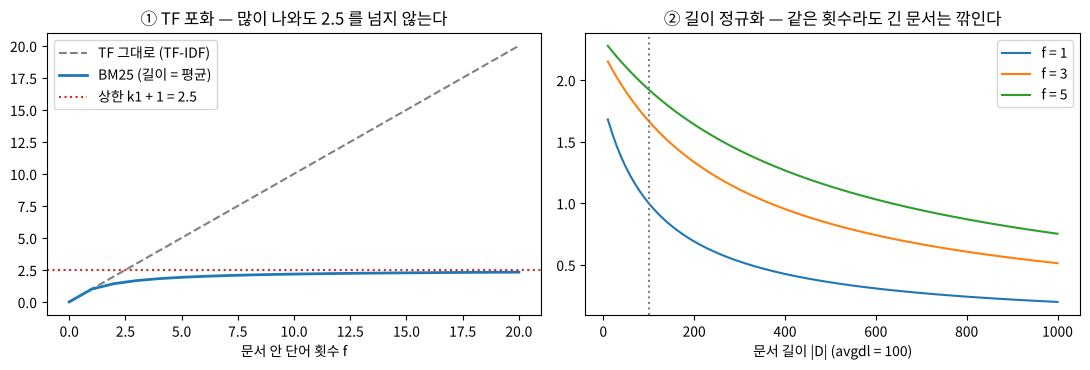

1,000단어 · 5번 → 1.663   |   50단어 · 3번 → 2.154  (IDF 는 같으니 이 부분만 비교)


In [5]:
def bm25_tf(f, doc_len, avgdl, k1=1.5, b=0.75):
    return f * (k1 + 1) / (f + k1 * (1 - b + b * doc_len / avgdl))

fs = np.arange(0, 21)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(fs, fs, '--', color='gray', label='TF 그대로 (TF-IDF)')
axes[0].plot(fs, [bm25_tf(f, 100, 100) for f in fs], color='C0', lw=2, label='BM25 (길이 = 평균)')
axes[0].axhline(2.5, color='C3', ls=':', label='상한 k1 + 1 = 2.5')
axes[0].set_xlabel('문서 안 단어 횟수 f'); axes[0].set_title('① TF 포화 — 많이 나와도 2.5 를 넘지 않는다'); axes[0].legend()
lens = np.arange(10, 1001, 10)
for f in [1, 3, 5]:
    axes[1].plot(lens, [bm25_tf(f, L, 100) for L in lens], label=f'f = {f}')
axes[1].axvline(100, color='gray', ls=':'); axes[1].set_xlabel('문서 길이 |D| (avgdl = 100)')
axes[1].set_title('② 길이 정규화 — 같은 횟수라도 긴 문서는 깎인다'); axes[1].legend()
plt.tight_layout(); plt.show()

# 교재 p.58 예시 : 1,000 단어 중 5번 vs 50 단어 중 3번 (avgdl 은 두 문서의 평균 525 로 가정)
avgdl = (1000 + 50) / 2
print(f'1,000단어 · 5번 → {bm25_tf(5, 1000, avgdl):.3f}   |   50단어 · 3번 → {bm25_tf(3, 50, avgdl):.3f}  (IDF 는 같으니 이 부분만 비교)')

- 교재 p.58 의 주장(짧은 글의 3번이 긴 글의 5번보다 관련성이 높다)은 공식으로 계산해도 맞다. 교재 문장은 '… 관련성이 높다고' 에서 끊겨 있다 → '**본다**'
- 📝 교재 p.57 'IDF = 단어가 등장한 문서 수의 역수 (N/DF)' → BM25 의 IDF 는 $\ln\frac{N - DF + 0.5}{DF + 0.5}$ (Lucene 등은 여기에 `+1` 을 넣어 음수를 막는다). 역수 그대로가 아니라 **로그**

## 3. 한글은 형태소로 (교재 p.59 · 필기 `RAG_실습4`)

In [6]:
documents = TextLoader(file_path='manual.txt', encoding='utf-8').load()
docs = RecursiveCharacterTextSplitter(chunk_size=160, chunk_overlap=0).split_documents(documents)
print('청크', len(docs), '개 (= QA 10쌍)')

청크 10 개 (= QA 10쌍)


In [7]:
from mecab import MeCab
mecab = MeCab()

def mecab_tokenizer(text):
    '''수업 함수 : 품사가 N(명사) · V(용언) · S(기호 · 외국어 · 숫자) 로 시작하는 형태소만'''
    return [morph for morph, pos in mecab.pos(text) if pos.startswith(('N', 'V', 'S'))]

print(mecab.pos('수강 신청한 강의를 환불하고 싶어요.'))
print('→', mecab_tokenizer('수강 신청한 강의를 환불하고 싶어요.'))

[('수강', 'NNG'), ('신청', 'NNG'), ('한', 'XSA+ETM'), ('강의', 'NNG'), ('를', 'JKO'), ('환불', 'NNG'), ('하', 'XSV'), ('고', 'EC'), ('싶', 'VX'), ('어요', 'EF'), ('.', 'SF')]
→ ['수강', '신청', '강의', '환불', '싶', '.']


> **📝 고친 부분 (필기 `RAG_실습4` cell 9)** 토큰화 함수가 `for` 에서 끊겨 있었다 → 강의본(`RAG_실습5_1`)과 같은 내용으로 완성. 함수 설명 'S : 숫자 및 외국어, 기호 등 (SN, SL 등)' 대로 `S` 는 **문장부호**(`SF` 마침표 · `SY` 붙임표 · `SC` 쉼표 …)까지 포함한다 → 위 결과의 `.` 도 토큰이 됐다. `V` 는 지정사 `VCP`('이다' 의 '이')까지 들어간다

In [8]:
split_retriever = BM25Retriever.from_documents(docs, preprocess_func=str.split, k=2)        # 띄어쓰기로만
mecab_retriever = BM25Retriever.from_documents(docs, preprocess_func=mecab_tokenizer, k=2)  # 형태소로
first_q = lambda ds: [d.page_content.splitlines()[0][4:24] for d in ds]
rows = []
for q in ['환불하고 싶어요', '수료증 발급되나요?', '모바일로 들을 수 있나요', '결제는 뭘로 해요?', '동영상이 끊겨요']:
    rows.append({'질문': q, '띄어쓰기 토큰': str.split(q), '띄어쓰기 1등': first_q(split_retriever.invoke(q))[0],
                 '띄어쓰기 점수 합': round(split_retriever.vectorizer.get_scores(str.split(q)).sum(), 2),
                 'MeCab 1등': first_q(mecab_retriever.invoke(q))[0]})
pd.DataFrame(rows)

,질문,띄어쓰기 토큰,띄어쓰기 1등,띄어쓰기 점수 합,MeCab 1등
0,환불하고 싶어요,"[환불하고, 싶어요]",수강 신청한 강의를 환불하고 싶어요.,1.85,수강 신청한 강의를 환불하고 싶어요.
1,수료증 발급되나요?,"[수료증, 발급되나요?]",모바일 앱으로도 강의를 들을 수 있나,0.00,강의를 다 들으면 수료증을 받을 수
2,모바일로 들을 수 있나요,"[모바일로, 들을, 수, 있나요]",모바일 앱으로도 강의를 들을 수 있나,4.85,모바일 앱으로도 강의를 들을 수 있나
3,결제는 뭘로 해요?,"[결제는, 뭘로, 해요?]",모바일 앱으로도 강의를 들을 수 있나,0.00,어떤 결제 수단을 사용할 수 있나요?
4,동영상이 끊겨요,"[동영상이, 끊겨요]",강의 동영상이 자꾸 끊기거나 재생되지,1.77,강의 동영상이 자꾸 끊기거나 재생되지


- 띄어쓰기로 자르면 `수료증` ↔ 매뉴얼의 `수료증을`, `결제는` ↔ `결제`·`결제일로부터` 처럼 **조사 · 어미가 붙은 덩어리**끼리 비교한다 — '수료증 발급되나요?' · '결제는 뭘로 해요?' 는 점수 합이 **0** 이라 상관없는 문서(모바일 앱)가 1등
- 띄어쓰기로 맞힌 3개는 질문을 매뉴얼 문장과 **똑같은 모양**(`환불하고 싶어요` · `들을 수 있나요` · `동영상이`)으로 썼을 때뿐이다
- 형태소로 자르면 5개 모두 맞는다 — `환불` · `수료증` · `모바일` · `결제` 가 조사 · 어미와 떨어져 맞아떨어진다 (교재 p.59 '형태소 단위 토큰화 전처리가 필수')

## 4. 손으로 계산한 BM25 = `rank_bm25`

In [9]:
bm25 = mecab_retriever.vectorizer                          # rank_bm25.BM25Okapi
corpus_tokens = [mecab_tokenizer(d.page_content) for d in docs]
q_tokens = mecab_tokenizer('환불하고 싶어요')
print('질문 토큰 :', q_tokens, '| 문서 수', bm25.corpus_size, '| 평균 길이', round(bm25.avgdl, 1))

def my_idf(word):
    n = sum(word in toks for toks in corpus_tokens)
    return math.log((len(corpus_tokens) - n + 0.5) / (n + 0.5)), n

for w in q_tokens + ['질문', '답변', ':']:
    raw_idf, n = my_idf(w)
    print(f'  {w!r:8s} 나온 문서 {n:2d}/10 · 공식 IDF {raw_idf:+.3f} · rank_bm25 IDF {bm25.idf.get(w, 0):.3f}')
print('  음수 IDF 대신 넣는 값 = 0.25 × 평균 IDF =', round(bm25.epsilon * bm25.average_idf, 3))

def my_score(q, toks):
    s = 0
    for w in q:
        f = toks.count(w)
        s += bm25.idf.get(w, 0) * f * (bm25.k1 + 1) / (f + bm25.k1 * (1 - bm25.b + bm25.b * len(toks) / bm25.avgdl))
    return s
mine = np.array([my_score(q_tokens, t) for t in corpus_tokens])
print('\n손계산 :', mine.round(3)); print('rank_bm25 :', bm25.get_scores(q_tokens).round(3)); print('같다 :', np.allclose(mine, bm25.get_scores(q_tokens)))

질문 토큰 : ['환불', '싶'] | 문서 수 10 | 평균 길이 40.3
  '환불'     나온 문서  1/10 · 공식 IDF +1.846 · rank_bm25 IDF 1.846
  '싶'      나온 문서  1/10 · 공식 IDF +1.846 · rank_bm25 IDF 1.846
  '질문'     나온 문서 10/10 · 공식 IDF -3.045 · rank_bm25 IDF 0.371
  '답변'     나온 문서 10/10 · 공식 IDF -3.045 · rank_bm25 IDF 0.371
  ':'      나온 문서 10/10 · 공식 IDF -3.045 · rank_bm25 IDF 0.371
  음수 IDF 대신 넣는 값 = 0.25 × 평균 IDF = 0.371

손계산 : [0.    5.102 0.    0.    0.    0.    0.    0.    0.    0.   ]
rank_bm25 : [0.    5.102 0.    0.    0.    0.    0.    0.    0.    0.   ]
같다 : True


- `질문` · `답변` · `:` 은 10개 문서 **모두**에 나온다 → 공식 IDF 가 음수(−3.045) → 0.371 로 바뀐다. 문서마다 똑같이 들어가니 순위에는 영향이 없다 — 사실상 **불용어**
- 질문 토큰 `환불` · `싶` 은 둘 다 2번 문서에만 있어(IDF 1.846) 2번만 점수를 받았다 — 교재 p.57 'X-2201 처럼 드문 단어는 IDF 가 크다' 와 같은 원리

## 5. 기술 지원 매뉴얼 — 코드 · 조항 검색 (교재 p.55~56 · 60)

In [10]:
tech_docs = RecursiveCharacterTextSplitter(chunk_size=210, chunk_overlap=0).split_documents(
    TextLoader('tech_support_manual.txt', encoding='utf-8').load())
tech_retriever = BM25Retriever.from_documents(tech_docs, preprocess_func=mecab_tokenizer, k=2)
print('청크', len(tech_docs), '개')
for q in ['ERR-502 오류코드 조치법', 'SD-301 해결법', 'NET-104 떠요', '제14조 2항', '8080 포트', '서비스 정책 제7조']:
    scores = tech_retriever.vectorizer.get_scores(mecab_tokenizer(q))
    top = np.argsort(-scores)[:2]
    print(f'{q:20s} → ' + ' | '.join(f'{scores[i]:.2f} {tech_docs[i].page_content[4:30]}' for i in top))

청크 8 개
ERR-502 오류코드 조치법     → 7.17 스마트 허브 모델 SH-M200X의 전원 오류  | 3.76 스마트 카메라 CAM-PRO-300의 SD 카드
SD-301 해결법           → 7.36 스마트 카메라 CAM-PRO-300의 SD 카드 | 0.57 스마트 허브 모델 SH-M200X의 전원 오류 
NET-104 떠요           → 5.50 앱에서 네트워크 연결 안 됨 상태로 표시되고 코 | 0.59 스마트 카메라 CAM-PRO-300의 SD 카드
제14조 2항              → 4.87 도어락 모델 DL-900 시리즈의 비상 비밀번호 | 1.99 보증 기간 내 무상 수리 및 환불 규정(서비스 
8080 포트              → 4.30 앱에서 네트워크 연결 안 됨 상태로 표시되고 코 | 0.00 스마트 허브 모델 SH-M200X의 전원 오류 
서비스 정책 제7조           → 4.66 보증 기간 내 무상 수리 및 환불 규정(서비스  | 1.32 도어락 모델 DL-900 시리즈의 비상 비밀번호


In [11]:
# MeCab 은 코드를 조각낸다 — 'SH-M200X' · 'ERR-502'
for code in ['SH-M200X', 'ERR-502', 'CAM-PRO-300', '12V/2A']:
    print(f'{code:12s} → {mecab_tokenizer(code)}')

SH-M200X     → ['SH', '-', 'M', '200', 'X']
ERR-502      → ['ERR', '-', '502']
CAM-PRO-300  → ['CAM', '-', 'PRO', '-', '300']
12V/2A       → ['12', 'V', '/', '2', 'A']


In [12]:
# 개선 토크나이저 : 코드(영문-숫자 묶음)는 통째로 남기고, 문장부호는 버리고, 영어는 소문자로
CODE = re.compile(r'[A-Za-z]+[A-Za-z0-9]*(?:-[A-Za-z0-9]+)+')
KEEP = ('NN', 'VV', 'VA', 'XR', 'SL', 'SN', 'MAG')               # 명사 · 동사 · 형용사 · 어근 · 외국어 · 숫자 · 부사

def code_aware_tokenizer(text):
    codes = [c.upper() for c in CODE.findall(text)]
    rest = CODE.sub(' ', text)
    return codes + [m.lower() for m, pos in mecab.pos(rest) if pos.startswith(KEEP)]

print(code_aware_tokenizer('스마트 허브 모델 SH-M200X의 전원 오류 코드 ERR-502가 표시되면?'))
better = BM25Retriever.from_documents(tech_docs, preprocess_func=code_aware_tokenizer, k=2)
for q in ['ERR-503 오류는 뭔가요?', 'err-502', 'M200X 모델']:
    print(f'{q:16s} 수업 함수 {[d.page_content[4:18] for d in tech_retriever.invoke(q)]} | 개선 {[d.page_content[4:18] for d in better.invoke(q)]}')

['SH-M200X', 'ERR-502', '스마트', '허브', '모델', '전원', '오류', '코드', '표시']
ERR-503 오류는 뭔가요? 수업 함수 ['스마트 허브 모델 SH-M', '스마트 카메라 CAM-PR'] | 개선 ['스마트 카메라 CAM-PR', '스마트 허브 모델 SH-M']
err-502          수업 함수 ['스마트 허브 모델 SH-M', '스마트 카메라 CAM-PR'] | 개선 ['스마트 허브 모델 SH-M', '보증 기간 내 무상 수리 ']
M200X 모델         수업 함수 ['스마트 허브 모델 SH-M', '도어락 모델 DL-900 '] | 개선 ['스마트 허브 모델 SH-M', '도어락 모델 DL-900 ']


- 수업 함수는 `ERR-502` 를 `ERR` · `-` · `502` 로 나눈다. 그래서 매뉴얼에 **없는** `ERR-503` 을 물어도 `ERR` · `오류` 가 겹치는 ERR-502 문서가 1등 — LLM 이 'ERR-503 은 어댑터 오류' 라고 **잘못 답할 위험**이 있다(프롬프트 규칙 3 '없으면 없다고' 가 중요한 이유)
- 개선 함수는 코드를 한 덩어리로 남겨 `ERR-503` 은 어느 문서에도 없는 토큰이 된다 — ERR-502 문서가 특별히 앞서지 않고 '오류' 같은 남은 낱말로만 순위가 정해진다(그래도 k개는 돌려준다, §6). 소문자 `err-502` 도 대문자로 맞춰 찾는다
- 대신 `M200X` 처럼 **코드의 일부만** 물으면 코드 토큰 `SH-M200X` 와는 맞지 않는다(위에서는 `모델` 이 겹쳐 찾았다) — 무엇을 토큰으로 볼지는 데이터와 질문 모양에 맞춰 정한다

## 6. 📝 BM25 는 점수가 0 이어도 k개를 돌려준다

In [13]:
q = '프린터 용지가 걸렸어요'                       # 매뉴얼에 없는 내용
print('질문 토큰 :', mecab_tokenizer(q))
print('문서별 점수 :', tech_retriever.vectorizer.get_scores(mecab_tokenizer(q)).round(2))
print('돌려준 문서 :', [d.page_content[4:24] for d in tech_retriever.invoke(q)], '← 점수가 모두 0 인데도 2개')

def positive_only(retriever):
    '''점수가 0 보다 큰 문서만 돌려주는 BM25 검색 함수'''
    def search(query):
        scores = retriever.vectorizer.get_scores(retriever.preprocess_func(query))
        order = [i for i in np.argsort(-scores, kind='stable') if scores[i] > 0][:retriever.k]
        return [retriever.docs[i] for i in order]
    return search
print('0점 거르기 :', positive_only(tech_retriever)(q))
print('\n비교 — 컴퓨터 화면이 안 켜져요 :', tech_retriever.vectorizer.get_scores(mecab_tokenizer('컴퓨터 화면이 안 켜져요')).round(2), "← '화면' 하나가 겹쳐 5번만 점수")

질문 토큰 : ['프린터', '용지', '걸렸']
문서별 점수 : [0. 0. 0. 0. 0. 0. 0. 0.]
돌려준 문서 : ['보증 기간 내 무상 수리 및 환불 규', '서비스 이용료 자동 결제 수단 변경 '] ← 점수가 모두 0 인데도 2개
0점 거르기 : []

비교 — 컴퓨터 화면이 안 켜져요 : [0.   0.   0.   0.   2.51 0.   0.   0.  ] ← '화면' 하나가 겹쳐 5번만 점수


- 겹치는 단어가 하나도 없으면 BM25 점수는 모두 0 — 그래도 `BM25Retriever` 는 **k개**를 돌려준다(점수가 같으면 문서 순서의 **뒤에서부터** — 여기서는 8번 · 7번). 하이브리드 검색에 그대로 넣으면 이 무작위 문서가 순위에 섞인다([`hybrid_search_rrf.ipynb`](./hybrid_search_rrf.ipynb) §5)
- '컴퓨터 화면이 안 켜져요' 는 매뉴얼 5번의 `화면` 한 단어가 겹쳐 겨우 찾았다. '컴퓨터' ↔ '기기', '안 켜져요' ↔ '먹통 · 반응도 없을 때' 는 BM25 에게 다른 단어다 — 교재 p.60 단점 '동의어 · 유의어 미인식'

## 정리

| | TF-IDF | BM25 |
|---|---|---|
| TF | 횟수 그대로 | 포화 — 많아도 $k_1 + 1$ 을 넘지 않음 |
| 문서 길이 | (sklearn 은 벡터 길이로 나눔) | $b$ 로 평균보다 긴 문서를 깎음 |
| IDF | $\log$ · 정리 자료의 N/DF 는 단순형 | $\ln\frac{N-DF+0.5}{DF+0.5}$ · 음수는 작은 값으로 |
| 한글 | 형태소 토큰화 필수 | 같음 — `preprocess_func=mecab_tokenizer` |
| 점수 0 | — | 그래도 k개를 돌려줌 → 걸러야 함 |